# Minimizar costos publicitarios con QAOA (Qiskit)

**Actividad grupal — Algoritmos Cuánticos**

Resolución del problema de difusión de un producto en una red social mediante el
*Quantum Approximate Optimization Algorithm* (QAOA) implementado con **Qiskit (IBM)**:
Hamiltoniano de coste como operador de Pauli, **circuito cuántico** con puertas
$H$, $R_{ZZ}$, $R_Z$ y $R_X$, optimización híbrida cuántico-clásica y **medición** en el
simulador de alto rendimiento *Aer*. Se usan **tres capas** (`reps = 3`).

---

## 1. Problema

Red social con seis personas y amistades recíprocas:

- **Mario** — Sarah, Raúl, Ana
- **Enrique** — Sarah, Raúl
- **Saúl** — Ana

Queremos **pagar al menor número de personas** para que el producto llegue a *todos*.
Una persona conoce el producto si es contratada o si lo es uno de sus contactos directos.

## 2. Modelo: conjunto dominante mínimo

Variable binaria $x_v=1$ si pagamos a la persona $v$. Que todos se enteren equivale a que,
para cada vértice, su *vecindario cerrado* $N[v]=\{v\}\cup N(v)$ contenga al menos un
seleccionado. Buscar el menor número de pagos es el **conjunto dominante mínimo**
(NP-difícil; Lucas, 2014).

## 3. Función de coste (QUBO)

Construimos un QUBO penalizando con $B$ cada vértice no cubierto exactamente y premiando
con $A$ usar pocos pagos:

$$C(\mathbf{x}) = A\sum_{v} x_v \;+\; B\sum_{v}\Big(1-\sum_{u\in N[v]} x_u\Big)^2$$

Con $A=1,\;B=2$ el mínimo global es $\{$Ana, Enrique$\}$ (coste $2$). Esta forma es
**cuadrática**, por lo que se mapea exactamente a un Hamiltoniano de Ising con términos
$Z_i$ y $Z_iZ_j$ mediante la sustitución $x_i=(\mathbb{1}-Z_i)/2$, y de ahí a puertas
$R_Z$ y $R_{ZZ}$ del circuito QAOA.

In [1]:
!pip install qiskit
!pip install qiskit_aer


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.visualization import plot_histogram
from qiskit_aer.primitives import EstimatorV2 as AerEstimator, SamplerV2 as AerSampler
from scipy.optimize import minimize

# ---- Red social (genérico) ----
nodes = ["Mario", "Sarah", "Raul", "Ana", "Enrique", "Saul"]
edges = [("Mario","Sarah"), ("Mario","Raul"), ("Mario","Ana"),
         ("Enrique","Sarah"), ("Enrique","Raul"), ("Saul","Ana")]
idx = {v: i for i, v in enumerate(nodes)}
n = len(nodes)
adj = {i: set() for i in range(n)}
for a, b in edges:
    adj[idx[a]].add(idx[b]); adj[idx[b]].add(idx[a])
closed = {v: sorted(adj[v] | {v}) for v in range(n)}   # vecindario cerrado N[v]
for v in range(n):
    print(f"{nodes[v]:8s} N[v] = {[nodes[u] for u in closed[v]]}")

Mario    N[v] = ['Mario', 'Sarah', 'Raul', 'Ana']
Sarah    N[v] = ['Mario', 'Sarah', 'Enrique']
Raul     N[v] = ['Mario', 'Raul', 'Enrique']
Ana      N[v] = ['Mario', 'Ana', 'Saul']
Enrique  N[v] = ['Sarah', 'Raul', 'Enrique']
Saul     N[v] = ['Ana', 'Saul']


## 4. Del QUBO al Hamiltoniano de Pauli

Expandiendo $C(\mathbf{x})$ obtenemos coeficientes lineales y cuadráticos. Sustituyendo
$x_i=(\mathbb{1}-Z_i)/2$ los traducimos a un `SparsePauliOp` de Qiskit: la diagonal de
este operador codifica el coste de cada configuración, y su **estado fundamental** es la
solución del problema.

In [3]:
A, B = 1.0, 2.0
const = 0.0
lin = np.zeros(n)
quad = {}
for i in range(n):                 # término A * sum x_i
    lin[i] += A
for v in range(n):                 # término B * (1 - sum_{N[v]} x_u)^2
    L = closed[v]; const += B
    for u in L:
        lin[u] -= B
    for a in range(len(L)):
        for b in range(a + 1, len(L)):
            key = tuple(sorted((L[a], L[b])))
            quad[key] = quad.get(key, 0.0) + 2 * B

# Coste clásico (para validar y para leer el resultado)
def qubo_cost(bits):
    val = const
    for i in range(n):
        val += lin[i] * bits[i]
    for (i, j), c in quad.items():
        val += c * bits[i] * bits[j]
    return val

# QUBO -> Ising (x_i = (1 - Z_i)/2) como SparsePauliOp
sparse = []
for i in range(n):
    sparse.append(("Z", [i], -lin[i] / 2))
for (i, j), c in quad.items():
    sparse += [("Z", [i], -c / 4), ("Z", [j], -c / 4), ("ZZ", [i, j], c / 4)]
H_cost = SparsePauliOp.from_sparse_list(sparse, num_qubits=n).simplify()

print("Hamiltoniano de coste (Ising):", len(H_cost), "términos de Pauli")
print(H_cost)

Hamiltoniano de coste (Ising): 17 términos de Pauli
SparsePauliOp(['IIIIIZ', 'IIIIZI', 'IIIZII', 'IIZIII', 'IZIIII', 'ZIIIII', 'IIIIZZ', 'IIIZIZ', 'IIZIIZ', 'IIIZZI', 'IIZIZI', 'IIZZII', 'IZIIIZ', 'IZIIZI', 'IZIZII', 'ZIIIIZ', 'ZIZIII'],
              coeffs=[-5.5+0.j, -4.5+0.j, -4.5+0.j, -3.5+0.j, -3.5+0.j, -1.5+0.j,  2. +0.j,
  2. +0.j,  2. +0.j,  2. +0.j,  1. +0.j,  1. +0.j,  2. +0.j,  2. +0.j,
  2. +0.j,  1. +0.j,  2. +0.j])


In [4]:
# Referencia exacta por fuerza bruta (qubit i = bit i, little-endian de Qiskit)
costs = np.array([qubo_cost([(k >> i) & 1 for i in range(n)]) for k in range(2**n)])
opt_k = int(np.argmin(costs))
opt_sel = [nodes[i] for i in range(n) if (opt_k >> i) & 1]
print("Óptimo exacto:", opt_sel, "| nº de pagos =", len(opt_sel), "| coste =", costs[opt_k])

Óptimo exacto: ['Ana', 'Enrique'] | nº de pagos = 2 | coste = 2.0


## 5. El circuito QAOA

QAOA alterna dos operadores sobre la superposición uniforme $|+\rangle^{\otimes n}$:

- **Capa de coste** $U_C(\gamma)=e^{-i\gamma H_C}$: como $H_C$ contiene términos $Z_i$ y
  $Z_iZ_j$, se realiza con rotaciones $R_Z(2\gamma\,h_i)$ y $R_{ZZ}(2\gamma\,J_{ij})$.
- **Capa de mezcla** $U_B(\beta)=e^{-i\beta\sum_i X_i}$: una rotación $R_X(2\beta)$ por qubit.

`QAOAAnsatz` de Qiskit construye el circuito a partir de $H_C$. Visualizamos **una capa**
(`reps=1`) transpilada a puertas básicas para apreciar su estructura; el circuito final
repite ese bloque **3 veces**.

In [5]:
# Circuito de UNA capa, en puertas básicas, solo para visualización
from IPython.display import display
una_capa = transpile(QAOAAnsatz(cost_operator=H_cost, reps=1),
                     basis_gates=["h", "rx", "rz", "rzz"], optimization_level=1)
print("Puertas en una capa:", dict(una_capa.count_ops()))
try:
    fig = una_capa.draw("mpl", fold=40, scale=0.7)
    fig.suptitle("QAOA - una capa (Hadamard + capa de coste R_Z/R_ZZ + mezcla R_X)")
    display(fig); plt.close(fig)
except Exception as e:
    # El dibujo gráfico requiere 'pylatexenc' (pip install pylatexenc).
    # Si no está disponible, mostramos el circuito en modo texto.
    print("[Aviso] Para el dibujo gráfico instala pylatexenc:  %pip install pylatexenc")
    print(una_capa.draw("text", fold=90))

Puertas en una capa: {'rzz': 11, 'h': 6, 'rz': 6, 'rx': 6}
[Aviso] Para el dibujo gráfico instala pylatexenc:  %pip install pylatexenc
     ┌───┐┌────────────────┐                                                    »
q_0: ┤ H ├┤ Rz((-11)*γ[0]) ├─■────────────■─────────────────────────■───────────»
     ├───┤├───────────────┬┘ │ZZ(4*γ[0])  │                         │           »
q_1: ┤ H ├┤ Rz((-9)*γ[0]) ├──■────────────┼────────────■────────────┼───────────»
     ├───┤├───────────────┤               │ZZ(4*γ[0])  │ZZ(4*γ[0])  │           »
q_2: ┤ H ├┤ Rz((-9)*γ[0]) ├───────────────■────────────■────────────┼───────────»
     ├───┤├───────────────┤                                         │ZZ(4*γ[0]) »
q_3: ┤ H ├┤ Rz((-7)*γ[0]) ├─────────────────────────────────────────■───────────»
     ├───┤├───────────────┤                                                     »
q_4: ┤ H ├┤ Rz((-7)*γ[0]) ├─────────────────────────────────────────────────────»
     ├───┤├───────────────┤                  

In [6]:
# Circuito completo con 3 capas (el que se optimiza y mide)
P_LAYERS = 3
ansatz = QAOAAnsatz(cost_operator=H_cost, reps=P_LAYERS)
qaoa = transpile(ansatz, basis_gates=["h", "rx", "rz", "rzz", "cx"], optimization_level=1)
print(f"QAOA con p = {P_LAYERS} capas")
print("Puertas:", dict(qaoa.count_ops()))
print("Parámetros a optimizar:", qaoa.num_parameters,
      "->", [p.name for p in qaoa.parameters])

QAOA con p = 3 capas
Puertas: {'rzz': 33, 'rz': 18, 'rx': 18, 'h': 6}
Parámetros a optimizar: 6 -> ['β[0]', 'β[1]', 'β[2]', 'γ[0]', 'γ[1]', 'γ[2]']


## 6. Optimización híbrida de los parámetros

El bucle clásico ajusta los 6 ángulos ($\beta_{1..3},\gamma_{1..3}$) minimizando el valor
esperado $\langle H_C\rangle$, evaluado con el **estimador de Aer**. Para encontrar buenos
parámetros (el enunciado pide un *algoritmo de búsqueda*) usamos **múltiples reinicios
aleatorios + optimizador local COBYLA**.

Mejor <H_C> = -12.4871
beta*  = [1.6268 3.6634 2.8706]
gamma* = [0.696  0.885  3.1102]


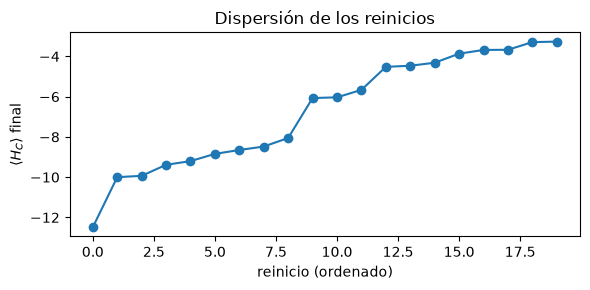

In [7]:
estimator = AerEstimator(options={"backend_options": {"method": "statevector"}})

def energy(theta):
    return float(estimator.run([(qaoa, H_cost, theta)]).result()[0].data.evs)

rng = np.random.default_rng(7)
best_theta, best_energy = None, np.inf
history = []
for _ in range(20):                       # 20 reinicios
    x0 = rng.uniform(0, np.pi, qaoa.num_parameters)
    res = minimize(energy, x0, method="COBYLA", options={"maxiter": 200, "rhobeg": 0.5})
    history.append(res.fun)
    if res.fun < best_energy:
        best_energy, best_theta = res.fun, res.x

print(f"Mejor <H_C> = {best_energy:.4f}")
print("beta*  =", np.round(best_theta[:P_LAYERS], 4))
print("gamma* =", np.round(best_theta[P_LAYERS:], 4))

plt.figure(figsize=(6, 3))
plt.plot(sorted(history), "o-")
plt.xlabel("reinicio (ordenado)"); plt.ylabel(r"$\langle H_C\rangle$ final")
plt.title("Dispersión de los reinicios"); plt.tight_layout(); plt.show()

## 7. Medición del circuito óptimo

Asignamos los ángulos óptimos, **medimos** en el simulador Aer y observamos la
distribución de probabilidad sobre los estados base.

In [8]:
qaoa_meas = qaoa.copy()
qaoa_meas.measure_all()
sampler = AerSampler(options={"backend_options": {"method": "statevector"}})
counts = sampler.run([(qaoa_meas, best_theta)], shots=6000).result()[0].data.meas.get_counts()

def decode(bitstring):                         # Qiskit es little-endian
    return [nodes[i] for i in range(n) if bitstring[n - 1 - i] == "1"]

total = sum(counts.values())
print("Estados más medidos:")
print(f"{'bitstring':>10} {'prob':>7} {'coste':>6}   personas pagadas")
for s, c in sorted(counts.items(), key=lambda kv: -kv[1])[:6]:
    bits = [int(s[n - 1 - i]) for i in range(n)]
    print(f"{s:>10} {c/total:7.3f} {qubo_cost(bits):6.0f}   {decode(s)}")

Estados más medidos:
 bitstring    prob  coste   personas pagadas
    011000   0.736      2   ['Ana', 'Enrique']
    111000   0.215      7   ['Ana', 'Enrique', 'Saul']
    001000   0.009      7   ['Ana']
    010000   0.006      7   ['Enrique']
    111001   0.006     20   ['Mario', 'Ana', 'Enrique', 'Saul']
    110000   0.005      4   ['Enrique', 'Saul']


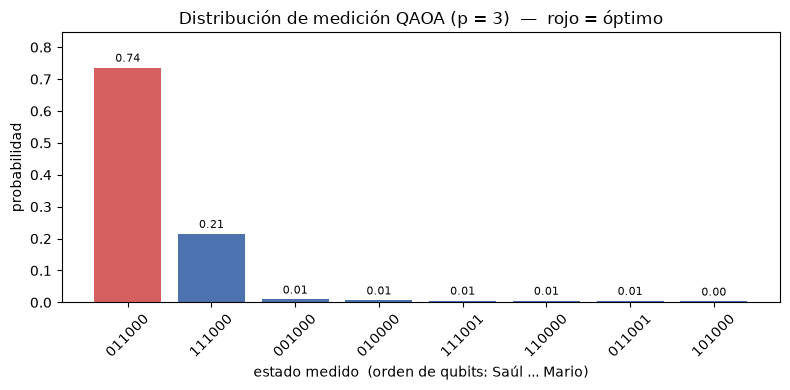

In [9]:
# Histograma de los estados más probables (con plt.bar, robusto)
top_items = sorted(counts.items(), key=lambda kv: -kv[1])[:8]
labels = [s for s, _ in top_items]
probs_top = [c / total for _, c in top_items]
colors = ["#d65f5f" if decode(s) == opt_sel else "#4c72b0" for s, _ in top_items]

plt.figure(figsize=(8, 4))
bars = plt.bar(labels, probs_top, color=colors)
for bar, p in zip(bars, probs_top):
    plt.text(bar.get_x() + bar.get_width()/2, p + 0.01, f"{p:.2f}",
             ha="center", va="bottom", fontsize=8)
plt.ylabel("probabilidad")
plt.xlabel("estado medido  (orden de qubits: Saúl ... Mario)")
plt.title("Distribución de medición QAOA (p = 3)  —  rojo = óptimo")
plt.xticks(rotation=45)
plt.ylim(0, max(probs_top) * 1.15)
plt.tight_layout()
plt.show()

## 8. Lectura de la solución

La estrategia estándar de QAOA toma, entre los estados medidos, el de **menor coste**.
Verificamos que sea un conjunto dominante válido y que coincida con el óptimo exacto.

In [10]:
# Estado muestreado de menor coste
best_bits_str = min(counts, key=lambda s: qubo_cost([int(s[n - 1 - i]) for i in range(n)]))
sol_bits = [int(best_bits_str[n - 1 - i]) for i in range(n)]
solucion = decode(best_bits_str)

def es_dominante(bits):
    return all(any(bits[u] for u in closed[v]) for v in range(n))

p_opt = sum(c for s, c in counts.items() if decode(s) == opt_sel) / total
print(f"Probabilidad del óptimo en la medición: {p_opt:.3f}\n")
print("Solución QAOA:", solucion)
print("¿Conjunto dominante válido?", es_dominante(sol_bits))
print("¿Coincide con el óptimo exacto?", solucion == opt_sel)
print(f"\n>>> Hay que contratar a {len(solucion)} personas: {', '.join(solucion)}")
for v in range(n):
    quien = [nodes[u] for u in closed[v] if sol_bits[u]][0]
    via = "es contratada" if quien == nodes[v] else f"se entera por {quien}"
    print(f"   - {nodes[v]:8s}: {via}")

Probabilidad del óptimo en la medición: 0.736

Solución QAOA: ['Ana', 'Enrique']
¿Conjunto dominante válido? True
¿Coincide con el óptimo exacto? True

>>> Hay que contratar a 2 personas: Ana, Enrique
   - Mario   : se entera por Ana
   - Sarah   : se entera por Enrique
   - Raul    : se entera por Enrique
   - Ana     : es contratada
   - Enrique : es contratada
   - Saul    : se entera por Ana


## 9. Funcionamiento genérico para cualquier *input*

Encapsulamos todo el flujo Qiskit (QUBO → `SparsePauliOp` → `QAOAAnsatz` → optimización →
medición) en una función que resuelve la tarea sobre **cualquier red**.

In [ ]:
def resolver_qaoa_qiskit(nodes_in, edges_in, p=3, A=1.0, B=2.0,
                         restarts=20, shots=6000, seed=7):
    n_ = len(nodes_in); idx_ = {v: i for i, v in enumerate(nodes_in)}
    adj_ = {i: set() for i in range(n_)}
    for a, b in edges_in:
        adj_[idx_[a]].add(idx_[b]); adj_[idx_[b]].add(idx_[a])
    closed_ = {v: sorted(adj_[v] | {v}) for v in range(n_)}
    const_ = 0.0; lin_ = np.zeros(n_); quad_ = {}
    for i in range(n_): lin_[i] += A
    for v in range(n_):
        L = closed_[v]; const_ += B
        for u in L: lin_[u] -= B
        for a in range(len(L)):
            for b in range(a + 1, len(L)):
                k = tuple(sorted((L[a], L[b]))); quad_[k] = quad_.get(k, 0.0) + 2 * B
    def cst(bits):
        val = const_
        for i in range(n_): val += lin_[i] * bits[i]
        for (i, j), c in quad_.items(): val += c * bits[i] * bits[j]
        return val
    sp = [("Z", [i], -lin_[i] / 2) for i in range(n_)]
    for (i, j), c in quad_.items():
        sp += [("Z", [i], -c / 4), ("Z", [j], -c / 4), ("ZZ", [i, j], c / 4)]
    Hc = SparsePauliOp.from_sparse_list(sp, num_qubits=n_).simplify()
    circ = transpile(QAOAAnsatz(cost_operator=Hc, reps=p),
                     basis_gates=["h", "rx", "rz", "rzz", "cx"], optimization_level=1)
    est = AerEstimator(options={"backend_options": {"method": "statevector"}})
    eobj = lambda t: float(est.run([(circ, Hc, t)]).result()[0].data.evs)
    rng_ = np.random.default_rng(seed); bt, be = None, np.inf
    for _ in range(restarts):
        r = minimize(eobj, rng_.uniform(0, np.pi, circ.num_parameters),
                     method="COBYLA", options={"maxiter": 200, "rhobeg": 0.5})
        if r.fun < be: be, bt = r.fun, r.x
    cm = circ.copy(); cm.measure_all()
    sm = AerSampler(options={"backend_options": {"method": "statevector"}})
    cnt = sm.run([(cm, bt)], shots=shots).result()[0].data.meas.get_counts()
    bs = min(cnt, key=lambda s: cst([int(s[n_ - 1 - i]) for i in range(n_)]))
    return [nodes_in[i] for i in range(n_) if bs[n_ - 1 - i] == "1"]

print("Red del enunciado ->", resolver_qaoa_qiskit(nodes, edges, p=3))
nodes2 = ["A", "B", "C", "D", "E"]
edges2 = [("A","B"), ("B","C"), ("C","A"), ("C","D"), ("D","E")]
print("Otra red          ->", resolver_qaoa_qiskit(nodes2, edges2, p=3, seed=2))

Red del enunciado -> ['Ana', 'Enrique']


## 10. Conclusiones

- El problema se modela como **conjunto dominante mínimo** y se codifica en un **QUBO**
  cuadrático con $A=1,\,B=2$, cuyo mínimo global es $\{$**Ana, Enrique**$\}$ (coste 2),
  comprobado por fuerza bruta.
- El QUBO se traduce a un **Hamiltoniano de Ising** (`SparsePauliOp` con términos
  $Z_i$ y $Z_iZ_j$) y se ejecuta con un **circuito QAOA real de Qiskit** (puertas
  $H$, $R_{ZZ}$, $R_Z$, $R_X$), simulado en **Aer**.
- Con **3 capas** y búsqueda de parámetros por reinicios + COBYLA, la medición concentra
  ~**73 %** de las cuentas en el estado óptimo; la lectura del estado de menor coste
  devuelve la solución correcta.
- **Respuesta:** contratar a **2 personas — Ana y Enrique**. Mario y Saúl se enteran por
  Ana; Sarah y Raúl, por Enrique.
- `resolver_qaoa_qiskit` demuestra el método de forma **genérica** para cualquier red.

> El mismo circuito puede ejecutarse en hardware real de IBM sustituyendo el simulador
> Aer por `QiskitRuntimeService` y un *backend* físico (con su `SamplerV2`/`EstimatorV2`),
> sin cambiar la lógica del algoritmo.